In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import fetch_openml
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (make_scorer, accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, roc_auc_score, average_precision_score,
                             precision_recall_curve, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [2]:
path = Path('../data/raw/mammography.csv')
if not path.exists():
    raw = fetch_openml('mammography', version=1, as_frame=True, parser='auto')
    df = raw.data.assign(target=raw.target)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)
df = pd.read_csv(path)

X = df.drop(columns='target')
minority = df['target'].value_counts().idxmin()   # редкий класс объявляем положительным (1)
y = (df['target'] == minority).astype(int)
print(X.shape, X.isna().sum().sum(), 'пропусков')
print(y.value_counts().to_dict(), f"дисбаланс 1:{(y == 0).sum() / (y == 1).sum():.0f}")

(11183, 6) 0 пропусков
{0: 10923, 1: 260} дисбаланс 1:42


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,     # tuning knob: доля теста
    stratify=y,        # держит долю редкого класса одинаковой в train и test, иначе в test может не оказаться положительных
    random_state=42,   # tuning knob: фиксирует разбиение
)
print(X_train.shape, X_test.shape, 'положительных:', y_train.sum(), y_test.sum())

(8946, 6) (2237, 6) положительных: 208 52


In [4]:
def make_model(kind):
    steps = [('scale', StandardScaler())]            # SMOTE считает расстояния, поэтому масштабируем до него
    if kind == 'smote':
        steps.append(('smote', SMOTE(random_state=42)))   # tuning knob: k_neighbors=5 по умолчанию
    weight = 'balanced' if kind == 'class_weight' else None
    steps.append(('clf', LogisticRegression(class_weight=weight, max_iter=1000)))
    return Pipeline(steps)

models = {name: make_model(name) for name in ['baseline', 'class_weight', 'smote']}

In [5]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)   # tuning knobs; один объект = одни и те же фолды у всех моделей
scoring = {
    'roc_auc':   'roc_auc',
    'pr_auc':    'average_precision',
    'precision': make_scorer(precision_score, zero_division=0),   # zero_division=0: если модель не предсказала ни одного положительного
    'recall':    make_scorer(recall_score),
    'f1':        make_scorer(f1_score, zero_division=0),
}
results = {name: cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
           for name, m in models.items()}    # если ячейка зависнет на Windows, поставь n_jobs=1

summary = pd.DataFrame({name: {k: f"{r['test_' + k].mean():.3f} ± {r['test_' + k].std():.3f}" for k in scoring}
                        for name, r in results.items()}).T
summary

,roc_auc,pr_auc,precision,recall,f1
baseline,0.905 ± 0.028,0.606 ± 0.057,0.803 ± 0.082,0.404 ± 0.076,0.533 ± 0.072
class_weight,0.914 ± 0.024,0.515 ± 0.054,0.158 ± 0.009,0.822 ± 0.049,0.265 ± 0.014
smote,0.912 ± 0.025,0.501 ± 0.057,0.158 ± 0.007,0.821 ± 0.053,0.265 ± 0.009


In [6]:
def compare(name, ref, metric):
    diff = results[name]['test_' + metric] - results[ref]['test_' + metric]   # 15 парных разностей: фолды одни и те же
    try:
        p = stats.wilcoxon(diff).pvalue          # H0: медиана разности равна 0
    except ValueError:                            # все разности нулевые
        p = np.nan
    return {'метод': name, 'против': ref, 'метрика': metric, 'ср. разность': diff.mean(),
            'лучше в фолдах': f'{(diff > 0).sum()}/{len(diff)}', 'p (Wilcoxon)': p}

pairs = [('class_weight', 'baseline'), ('smote', 'baseline'), ('smote', 'class_weight')]
pd.DataFrame([compare(n, r, k) for n, r in pairs for k in scoring]).round(4)

,метод,против,метрика,ср. разность,лучше в фолдах,p (Wilcoxon)
0,class_weight,baseline,roc_auc,0.0085,10/15,0.0215
1,class_weight,baseline,pr_auc,-0.0912,0/15,0.0001
2,class_weight,baseline,precision,-0.6450,0/15,0.0001
3,class_weight,baseline,recall,0.4183,15/15,0.0007
4,class_weight,baseline,f1,-0.2684,0/15,0.0001
5,smote,baseline,roc_auc,0.0073,11/15,0.0256
6,smote,baseline,pr_auc,-0.1050,0/15,0.0001
7,smote,baseline,precision,-0.6446,0/15,0.0001
8,smote,baseline,recall,0.4166,15/15,0.0007
9,smote,baseline,f1,-0.2679,0/15,0.0001


In [7]:
BEST = 'class_weight'   # tuning knob: поставь 'smote', если по ячейкам 5–6 он реально лучше

oof_proba = cross_val_predict(
    models[BEST], X_train, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    method='predict_proba', n_jobs=-1,
)[:, 1]      # для каждой строки train: вероятность от модели, которая эту строку не видела

prec, rec, thr = precision_recall_curve(y_train, oof_proba)
beta = 2     # tuning knob: во сколько раз recall важнее precision (см. формулу ниже)
fbeta = (1 + beta**2) * prec[:-1] * rec[:-1] / (beta**2 * prec[:-1] + rec[:-1] + 1e-12)
t_star = thr[np.argmax(fbeta)]
print(f'порог t* = {t_star:.3f}, F2 на OOF = {fbeta.max():.3f}')

порог t* = 0.819, F2 на OOF = 0.586


In [8]:
def report(name, model, threshold=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    row = {'модель': name, 'порог': round(threshold, 3),
           'accuracy': accuracy_score(y_test, pred),
           'precision': precision_score(y_test, pred, zero_division=0),
           'recall': recall_score(y_test, pred),
           'F1': f1_score(y_test, pred), 'F2': fbeta_score(y_test, pred, beta=2),
           'ROC-AUC': roc_auc_score(y_test, proba), 'PR-AUC': average_precision_score(y_test, proba)}
    return row, pred

base = models['baseline'].fit(X_train, y_train)
best = models[BEST].fit(X_train, y_train)
row1, pred1 = report('baseline', base)
row2, pred2 = report(BEST, best)
row3, pred3 = report(BEST, best, threshold=t_star)
print('accuracy у "всегда норма":', round(1 - y_test.mean(), 4))
pd.DataFrame([row1, row2, row3]).round(3)

accuracy у "всегда норма": 0.9768


,модель,порог,accuracy,precision,recall,F1,F2,ROC-AUC,PR-AUC
0,baseline,0.500,0.983,0.760,0.365,0.494,0.408,0.974,0.651
1,class_weight,0.500,0.904,0.191,0.962,0.318,0.532,0.967,0.613
2,class_weight,0.819,0.970,0.409,0.692,0.514,0.608,0.967,0.613


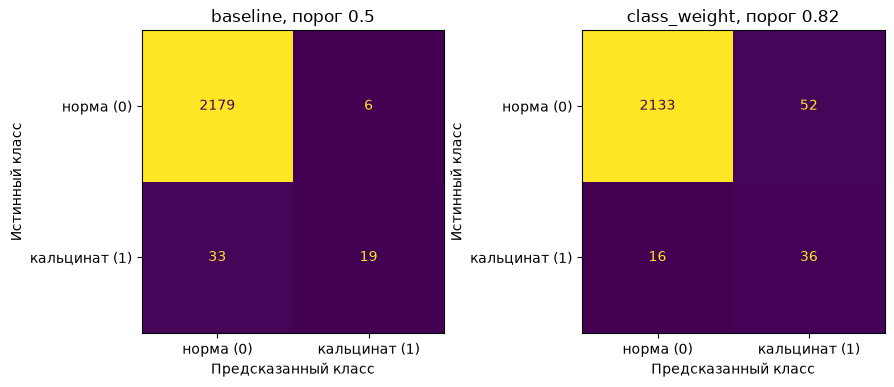

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, pred, title in zip(axes, [pred1, pred3], ['baseline, порог 0.5', f'{BEST}, порог {t_star:.2f}']):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['норма (0)', 'кальцинат (1)'],
                                            ax=ax, colorbar=False)
    ax.set_title(title); ax.set_xlabel('Предсказанный класс'); ax.set_ylabel('Истинный класс')
plt.tight_layout(); plt.show()

## Выводы

**Данные.** Mammography (OpenML): <N> строк, 6 числовых признаков, <K> положительных (кальцинаты), дисбаланс 1:<R>. Accuracy у модели «всегда норма» была бы <X>, поэтому качество оценивается по precision, recall, F1 и AUC.

**Схема сравнения.** Три модели (baseline, class_weight, SMOTE) оценены на одних и тех же фолдах: 5 фолдов × 3 повтора = 15 оценок на модель. SMOTE применяется только внутри обучающих фолдов (imblearn.Pipeline), чтобы не было утечки в проверочные.

**Результат.** Baseline: recall <..>, F1 <..> при пороге 0,5, то есть модель почти не находит положительные объекты. class_weight: recall <..>, precision <..>. SMOTE: recall <..>, precision <..>. Прирост recall по сравнению с baseline виден в <..>/15 фолдов (p = <..>), то есть не объясняется случайностью разбиения. ROC-AUC: <..> / <..> / <..> (<изменился мало / вырос>), значит, методы <в основном сдвинули порог / улучшили ранжирование>. Между class_weight и SMOTE разница <незначима / ..>.

**Предпочтительный метод:** <class_weight / SMOTE>, потому что <рекорд по recall при сопоставимой precision / проще и быстрее при статистически неотличимом качестве>.

**Порог.** Порог 0,5 допустим только для baseline как точка отсчёта. Для итоговой модели он выбран на out-of-fold предсказаниях train по F2 (β = 2), потому что пропуск кальцината (FN) опаснее ложной тревоги (FP): t* = <..>. На test при этом пороге recall = <..>, precision = <..> (по матрице: TP <..>, FP <..>, FN <..>, TN <..>). Порог выбирался только по train, test использован один раз.

**Что означает ROC-AUC = <..>.** Если взять случайный объект с кальцинатом и случайный без него, то с вероятностью <..> модель даст первому более высокую оценку. PR-AUC = <..> при случайном уровне около <доля положительных>.

**Ограничения.** В test всего около 52 положительных объектов, поэтому метрики на нём шумные. Данные одного источника, обобщение на другие аппараты не проверялось.